In [ ]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx

from src import constants
from src.graph_theory.utils.ripe_parser import parse_to_networkx

DATA_DIR = Path(os.environ.get("DATA_DIR"))
print(f"Data dir: {DATA_DIR}")

Data dir: /Users/Artsem_Nikitsenka/experimental-dsa-python/data


In [ ]:
def make_google_com_sample_100_graph():
    with open(
        DATA_DIR / "out/google_com_sample_100.ndjson", "r", encoding=constants.UTF8
    ) as file:
        file_content = file.read().splitlines()
    display(file_content)
    graph = parse_to_networkx(file_content)
    print(graph.nodes(data=True))
    print(graph.edges())
    return graph


network_graph = make_google_com_sample_100_graph()

['{"fw":5120,"mver":"2.6.4","lts":1958117,"endtime":1781915147,"dst_name":"google.com","ttr":4.500522,"dst_addr":"142.251.127.100","src_addr":"172.19.0.2","proto":"UDP","af":4,"size":48,"paris_id":6,"result":[{"hop":1,"result":[{"from":"172.19.0.1","ttl":64,"size":76,"rtt":0.499},{"from":"172.19.0.1","ttl":64,"size":76,"rtt":0.638},{"from":"172.19.0.1","ttl":64,"size":76,"rtt":0.632}]},{"hop":2,"result":[{"from":"192.168.21.250","ttl":64,"size":76,"rtt":2387.095,"err":"H"},{"from":"192.168.21.250","ttl":64,"size":76,"rtt":3059.72,"err":"H"},{"from":"192.168.21.250","ttl":64,"size":76,"rtt":3058.933,"err":"H"}]}],"destination_ip_responded":false,"msm_id":86691225,"prb_id":1003959,"timestamp":1781915139,"msm_name":"Traceroute","from":"178.203.223.0","type":"traceroute","group_id":86691224}',
 '{"fw":5120,"mver":"2.6.4","lts":1957228,"endtime":1781914258,"dst_name":"google.com","ttr":4.273166,"dst_addr":"142.251.127.139","src_addr":"172.19.0.2","proto":"UDP","af":4,"size":48,"paris_id":5,

[(0, {'ip': '172.19.0.2', 'label': '178.203.223.0', 'type': 'host', 'mac': None, 'vendor': None}), (1, {'ip': '142.251.127.100', 'label': 'google.com', 'type': 'host', 'mac': None, 'vendor': None}), (2, {'ip': '172.19.0.1', 'label': '172.19.0.1', 'type': 'router', 'mac': None, 'vendor': None}), (3, {'ip': '192.168.21.250', 'label': '192.168.21.250', 'type': 'router', 'mac': None, 'vendor': None}), (4, {'ip': '142.251.127.139', 'label': 'google.com', 'type': 'host', 'mac': None, 'vendor': None}), (5, {'ip': '2803:7780:3:15::2', 'label': '2803:7780:3:15::2', 'type': 'host', 'mac': None, 'vendor': None}), (6, {'ip': '2001:4860:4827:7700::', 'label': 'www.google.com', 'type': 'host', 'mac': None, 'vendor': None}), (7, {'ip': '10.33.30.31', 'label': '82.113.63.241', 'type': 'host', 'mac': None, 'vendor': None}), (8, {'ip': '142.251.38.142', 'label': 'google.com', 'type': 'host', 'mac': None, 'vendor': None}), (9, {'ip': '10.33.30.1', 'label': '10.33.30.1', 'type': 'router', 'mac': None, 've

NodeDataView({0: {'ip': '172.19.0.2', 'label': '178.203.223.0', 'type': 'host', 'mac': None, 'vendor': None}, 2: {'ip': '172.19.0.1', 'label': '172.19.0.1', 'type': 'router', 'mac': None, 'vendor': None}, 35: {'ip': '172.217.17.78', 'label': 'google.com', 'type': 'host', 'mac': None, 'vendor': None}, 37: {'ip': '92.52.10.1', 'label': '92.52.10.1', 'type': 'router', 'mac': None, 'vendor': None}, 38: {'ip': '192.168.115.21', 'label': '192.168.115.21', 'type': 'router', 'mac': None, 'vendor': None}, 39: {'ip': '213.151.198.238', 'label': '213.151.198.238', 'type': 'router', 'mac': None, 'vendor': None}, 40: {'ip': '185.0.20.171', 'label': '185.0.20.171', 'type': 'router', 'mac': None, 'vendor': None}, 41: {'ip': '192.178.252.183', 'label': '192.178.252.183', 'type': 'router', 'mac': None, 'vendor': None}, 42: {'ip': '192.178.98.40', 'label': '192.178.98.40', 'type': 'router', 'mac': None, 'vendor': None}, 43: {'ip': '192.178.86.119', 'label': '192.178.86.119', 'type': 'router', 'mac': Non

[0, 2, 21, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 35]

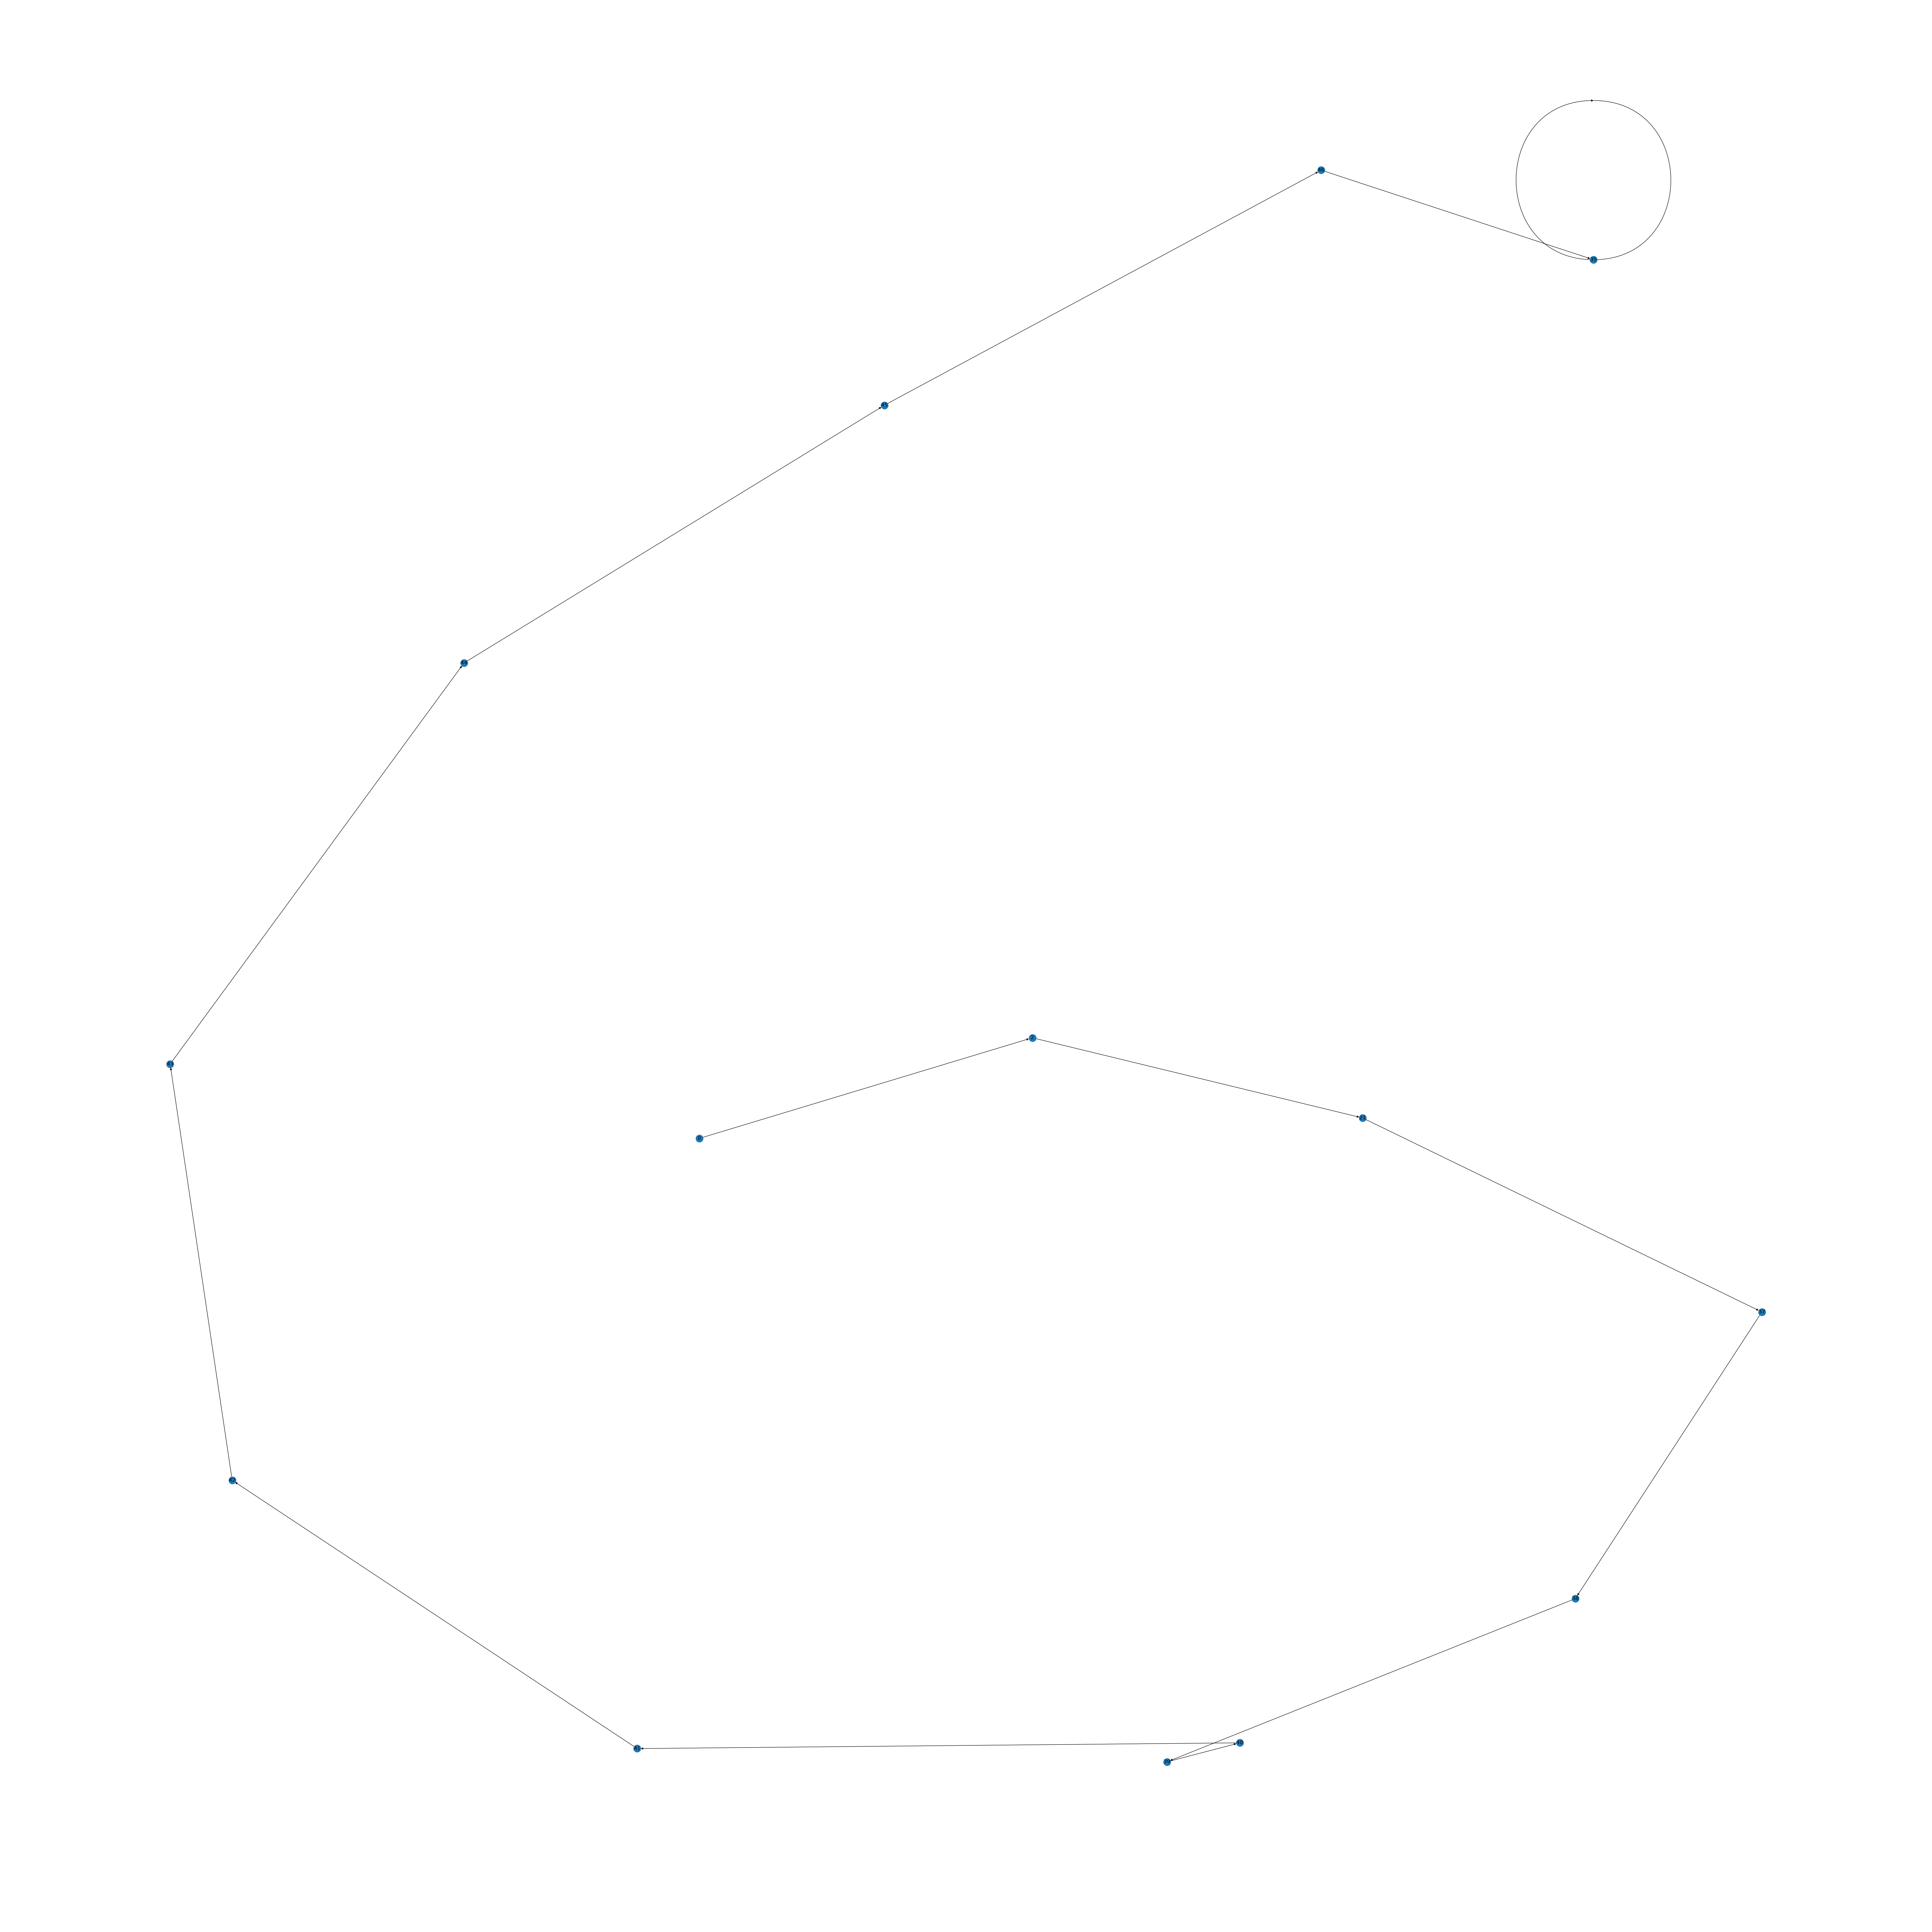

In [7]:
def find_dijkstra_shortest_path(graph: nx.DiGraph):
    return nx.dijkstra_path(graph, source=0, target=35, weight="link_rtt_ms")


def show_shortest_path(graph: nx.DiGraph, shortest_path: list[int]):
    display(graph.subgraph(shortest_path).nodes(data=True))
    display(shortest_path)
    plt.figure(figsize=(64, 64))
    nx.draw(graph.subgraph(shortest_path), with_labels=True)
    plt.show()


shortest_path = find_dijkstra_shortest_path(network_graph)
show_shortest_path(network_graph, shortest_path)

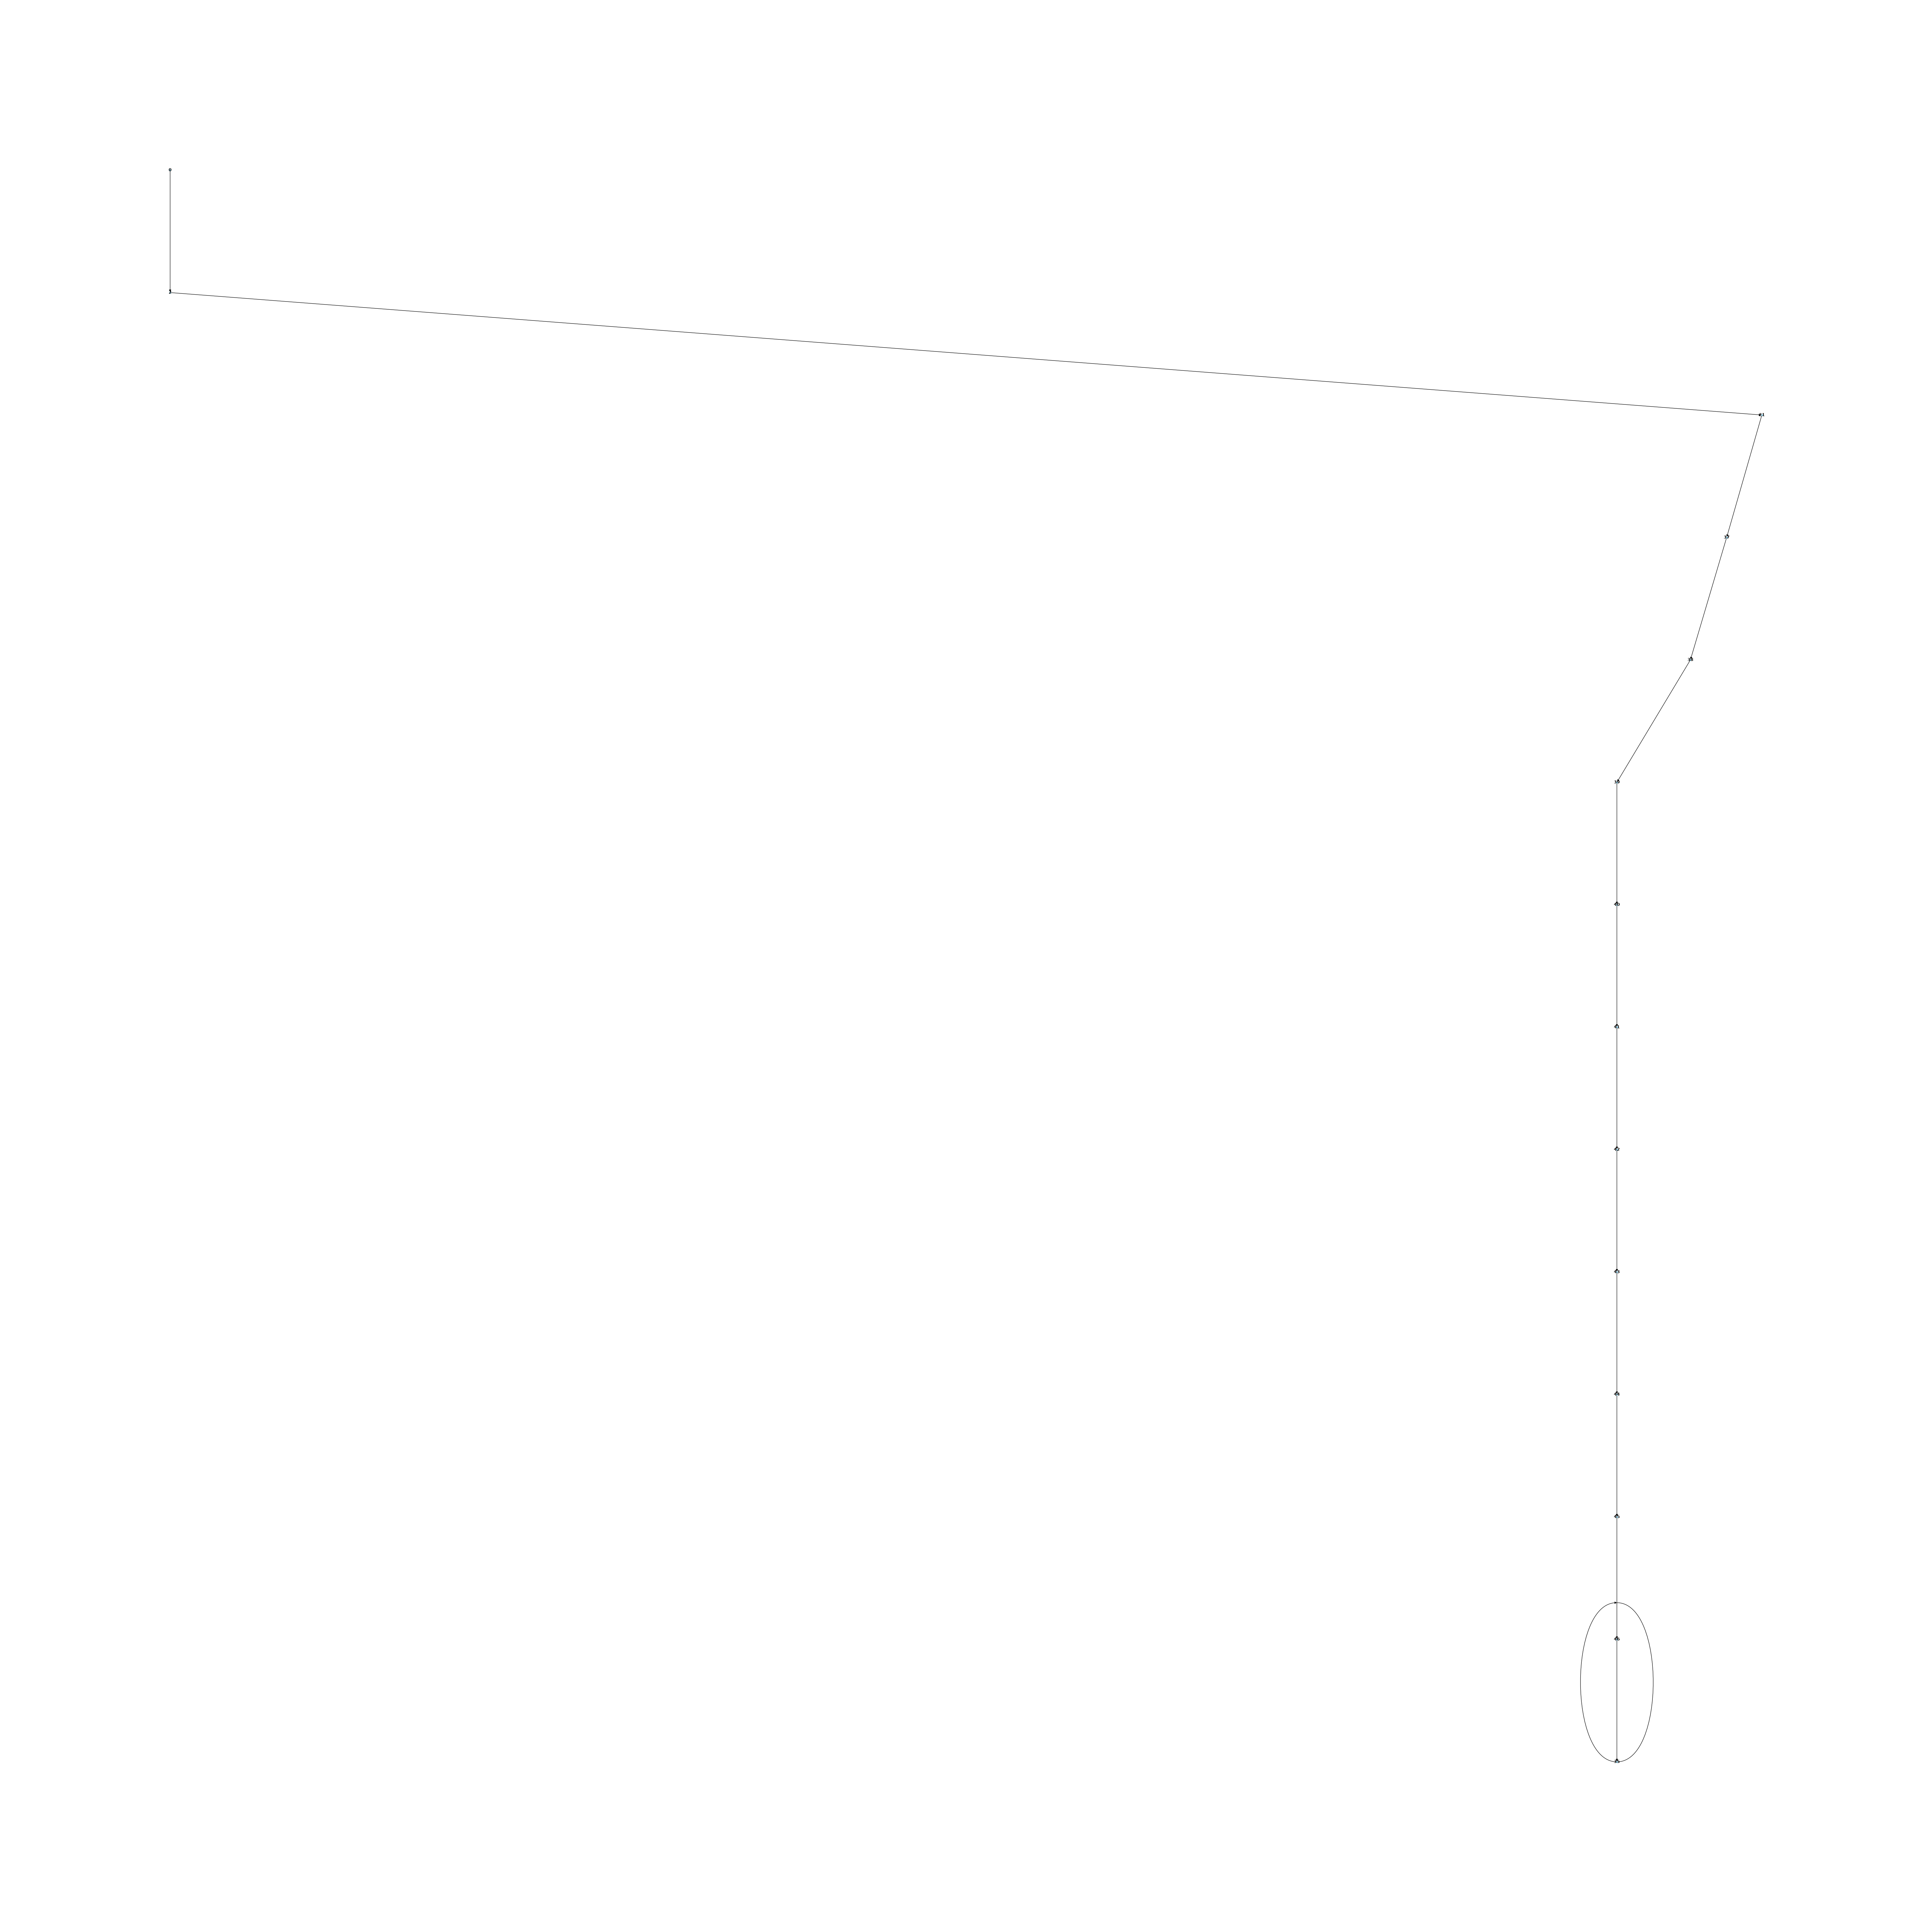

In [10]:
def show_shortest_path_graphviz(graph: nx.DiGraph, shortest_path: list[int]):
    node_positions = nx.nx_agraph.graphviz_layout(graph, prog="dot")

    plt.figure(figsize=(64, 64))
    nx.draw(
        graph.subgraph(shortest_path),
        node_positions,
        with_labels=True,
        node_size=10,
        node_color="skyblue",
        font_size=10,
        font_weight="bold",
        arrows=True,
    )
    plt.show()


show_shortest_path_graphviz(network_graph, shortest_path)